# Starting XI — Stage 3 results

Every Gameweek a Fantasy Premier League manager picks 11 starters from a 15-player squad. This notebook
shows how well a set of simple, rule-of-thumb ways of picking that XI did over the 2025-26 season,
on synthetic squads. Summarised on the decision card: [`CARD.md`](CARD.md) §3.

**Summary (ownership-weighted squads)**

1. The best rule, **D2 season** (season points per team fixture × the coming fixture count), misses
   about 2.56 points per squad per Gameweek against the hindsight-best XI, versus about 3.45 for a random XI.
2. That beats random by 0.89 points [0.40, 1.40]: about a quarter of the way from random to perfect.
3. Season-long rules beat last-3-Gameweek rules (by 0.24 points or more); among season rules, only
   the start-rate rule (D4) is clearly worse than D2.
4. Rules agree on 85–99% of their picks, so they differ at the margins, not wholesale.
5. Synthetic squads overstate goalkeeper misses and under-include premiums; real squads (Stage 5) settle that.

This notebook only presents. Every number comes from tested code in
[`report.py`](report.py); the cells below load, format and plot.

### Setup

**What:** loads the two saved runs and the 2025-26 warehouse data, and builds the report tables.
**Why:** every table and chart below reads from these objects, so all numbers trace to one place.
**How:** `report.build` summarises each run; `report.diagnose` re-draws each run's squads (checking they are
the run's own) to count who played and which formations were used. Runs: uniform `7d0882b01554c1cb`,
ownership `bdcc8b3f54f937b0`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from decisions.starting_xi import report, results
from operational.starting_xi import RESULTS_ROOT, SEASON
from warehouse import served

RUNS = {"uniform": "7d0882b01554c1cb", "ownership": "bdcc8b3f54f937b0"}
artefacts = {mode: results.read(RESULTS_ROOT, run_id) for mode, run_id in RUNS.items()}
frames = served.load(SEASON)
built = report.build(list(artefacts.values()))
diagnostics = report.diagnose([(a, report.squad_facts(frames, a)) for a in artefacts.values()])

LABELS = {
    "ppg_gameweek_season": "D1 season: points per gameweek",
    "ppg_fixture_season": "D2 season: points per fixture",
    "ppg_appearance_season": "D3 season: points per appearance",
    "ppg_start_season": "D4 season: points per start",
    "ppg_gameweek_last3": "D1 last 3: points per gameweek",
    "ppg_fixture_last3": "D2 last 3: points per fixture",
    "ppg_appearance_last3": "D3 last 3: points per appearance",
    "ppg_start_last3": "D4 last 3: points per start",
    "starts_rate_x_points_per_appearance": "Starts rate × points per appearance",
    "random": "Random XI",
}
MODE = "ownership"
pd.set_option("display.precision", 2)


def labelled(frame):
    return frame.rename(index=LABELS)

## (a) Points missed per rule

**What:** for each rule, the average points its XI missed compared with the best XI that could have
been picked from the same 15 in hindsight (*XI regret*), with a 95% range.
**Why:** this is the main score. Fewer missed points means a better pick, and the gap to random shows whether a
rule knows anything at all.
**How:** XI regret = best possible XI's points minus the chosen XI's points after automatic substitutions,
averaged over 300 squads × Gameweeks 4–38. The 95% range resamples whole blocks of Gameweeks, so it
reflects week-to-week luck. *Lower is better.* "Scale" places a rule between random (0%) and perfect hindsight (100%).

In [2]:
rules = built.rules.loc[MODE].astype(float).sort_values("xi_mean")
table = labelled(rules[["xi_mean", "xi_ci_lo", "xi_ci_hi", "xi_median", "xi_p90", "xi_scale_pct"]])
table.columns = ["Mean missed", "95% low", "95% high", "Median", "Worst 10% (P90)", "Scale %"]
table

,Mean missed,95% low,95% high,Median,Worst 10% (P90),Scale %
rule,,,,,,
D2 season: points per fixture,2.56,2.24,2.93,1.0,8.0,25.82
D3 season: points per appearance,2.58,2.26,2.97,1.0,8.0,25.42
Starts rate × points per appearance,2.59,2.30,2.94,1.0,8.0,25.13
D1 season: points per gameweek,2.59,2.31,2.94,1.0,8.0,24.89
D4 season: points per start,2.66,2.34,3.08,1.0,8.0,22.88
D2 last 3: points per fixture,2.80,2.44,3.23,1.0,9.0,19.01
D3 last 3: points per appearance,2.85,2.46,3.34,1.0,9.0,17.41
D1 last 3: points per gameweek,2.89,2.58,3.28,1.0,9.0,16.29
D4 last 3: points per start,2.92,2.56,3.41,1.0,9.0,15.56


**What:** the same averages and ranges as a chart.
**Why:** overlapping bars show at a glance which rules can be told apart.
**How:** each dot is a rule's mean points missed; the line is its 95% range. *Further left is better.*

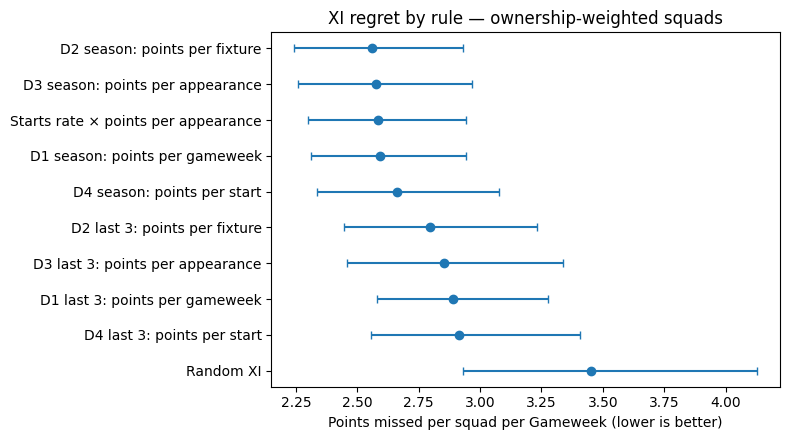

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y = range(len(table))
ax.errorbar(table["Mean missed"], y, xerr=[table["Mean missed"] - table["95% low"], table["95% high"] - table["Mean missed"]],
            fmt="o", capsize=3)
ax.set_yticks(list(y), table.index)
ax.invert_yaxis()
ax.set_xlabel("Points missed per squad per Gameweek (lower is better)")
ax.set_title("XI regret by rule — ownership-weighted squads")
plt.tight_layout()

## (b) Differences between rules

**What:** each rule's points missed minus random's, and minus D2 season's (the best rule), with 95% ranges.
**Why:** two rules' own ranges can overlap even when one is reliably better. Comparing them week by week
on the same squads is the fair test.
**How:** for each Gameweek, take the difference between the two rules' average misses, then resample those
weekly differences. *Negative means the rule misses fewer points.* A range that doesn't cross 0 means the
difference isn't luck.

In [4]:
differences = built.differences.loc[MODE].astype(float)
both = pd.concat(
    {"vs random": differences.loc["random"], "vs D2 season": differences.loc[report.REFERENCE_RULE]}, axis=1
)
both.columns = [f"{versus} {stat}" for versus, stat in both.columns]
labelled(both.sort_values("vs random mean_diff"))

,vs random mean_diff,vs random ci_lo,vs random ci_hi,vs D2 season mean_diff,vs D2 season ci_lo,vs D2 season ci_hi
rule,,,,,,
D2 season: points per fixture,-0.89,-1.40,-0.40,NaN,NaN,NaN
D3 season: points per appearance,-0.88,-1.40,-0.34,0.01,-3.70e-02,0.09
Starts rate × points per appearance,-0.87,-1.42,-0.33,0.02,-7.47e-02,0.13
D1 season: points per gameweek,-0.86,-1.38,-0.37,0.03,-6.00e-03,0.10
D4 season: points per start,-0.79,-1.33,-0.24,0.10,3.04e-02,0.20
D2 last 3: points per fixture,-0.66,-1.17,-0.14,0.24,3.13e-02,0.46
D3 last 3: points per appearance,-0.60,-1.11,-0.10,0.29,3.02e-02,0.59
D1 last 3: points per gameweek,-0.56,-1.10,-0.03,0.33,8.28e-02,0.60
D4 last 3: points per start,-0.54,-1.02,-0.06,0.35,1.23e-01,0.66


**What:** the two sets of differences as charts.
**Why:** shows which rules are clearly better than random, and which are clearly worse than D2.
**How:** dot = average difference, line = 95% range, dashed line = no difference. *A line that doesn't touch the
dashed line is a real difference.* Left panel: left of zero beats random. Right panel: right of zero is worse than D2.

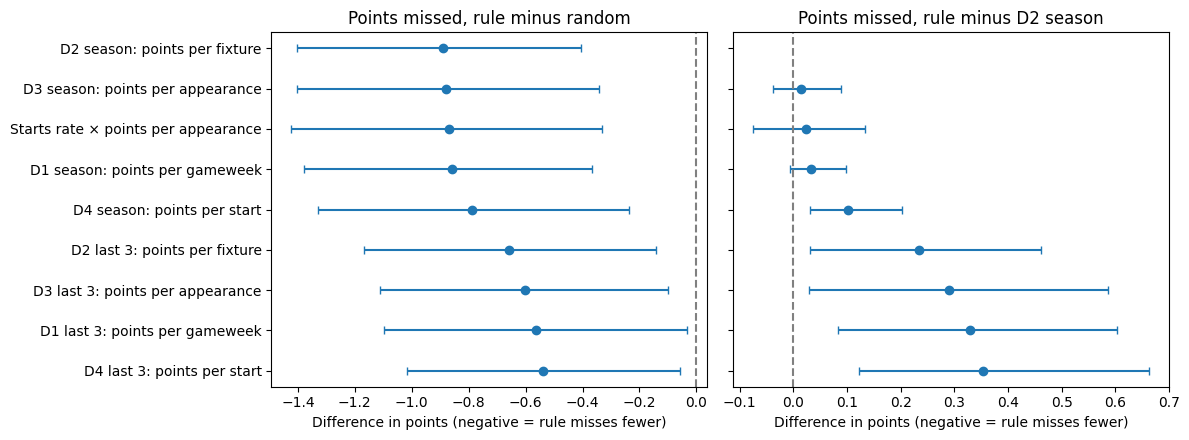

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
order = differences.loc["random"].sort_values("mean_diff").index
for ax, versus, title in zip(axes, ["random", report.REFERENCE_RULE], ["random", "D2 season"], strict=True):
    d = differences.loc[versus].reindex([r for r in order if r != versus])
    y = [list(order).index(r) for r in d.index]
    ax.errorbar(d["mean_diff"], y, xerr=[d["mean_diff"] - d["ci_lo"], d["ci_hi"] - d["mean_diff"]], fmt="o", capsize=3)
    ax.axvline(0, linestyle="--", color="grey")
    ax.set_title(f"Points missed, rule minus {title}")
    ax.set_xlabel("Difference in points (negative = rule misses fewer)")
axes[0].set_yticks(range(len(order)), [LABELS[r] for r in order])
axes[0].invert_yaxis()
plt.tight_layout()

## (c) By phase of the season

**What:** points missed by each rule in three parts of the season: Gameweeks 4–12, 13–26 and 27–38.
**Why:** a rule built on season averages has little to go on early; if it only works late, that matters for
when to trust it.
**How:** the same XI regret, averaged within each phase. *Lower is better.* No ranges here: this is a
description of where misses fall, not a test.

In [6]:
phases = built.phases.loc[MODE, "mean"].astype(float).unstack("phase")[["4-12", "13-26", "27-38"]]
phases = phases.loc[rules.index]
labelled(phases)

phase,4-12,13-26,27-38
rule,,,
D2 season: points per fixture,2.94,2.80,2.00
D3 season: points per appearance,2.95,2.83,1.99
Starts rate × points per appearance,2.81,2.84,2.12
D1 season: points per gameweek,2.94,2.80,2.08
D4 season: points per start,3.02,2.96,2.04
D2 last 3: points per fixture,3.28,3.04,2.14
D3 last 3: points per appearance,3.42,3.02,2.23
D1 last 3: points per gameweek,3.28,3.05,2.40
D4 last 3: points per start,3.44,3.04,2.37


**What:** the phase table as a chart, for D2 season, the best last-3 rule and random.
**Why:** shows whether the gap between a good rule and random holds across the season.
**How:** one line per rule across the three phases. *Lower is better.*

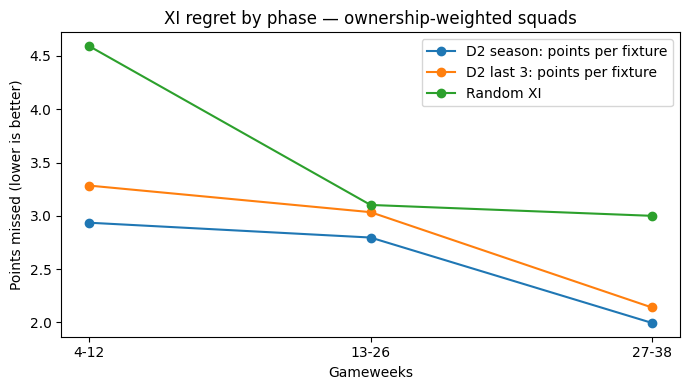

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for rule in [report.REFERENCE_RULE, "ppg_fixture_last3", "random"]:
    ax.plot(phases.columns, phases.loc[rule], marker="o", label=LABELS[rule])
ax.set_xlabel("Gameweeks")
ax.set_ylabel("Points missed (lower is better)")
ax.legend()
ax.set_title("XI regret by phase — ownership-weighted squads")
plt.tight_layout()

## (d) By position

**What:** where in the XI the missed points come from: goalkeeper, defenders, midfielders, forwards.
**Why:** tells us which positional choices a rule gets wrong, and whether one position distorts the totals.
**How:** at each position, the best XI's points there minus the chosen XI's points there. The four add up to
the total. A position can be negative when a rule does better there than the best XI did, at the cost of
another position. *Lower is better.*

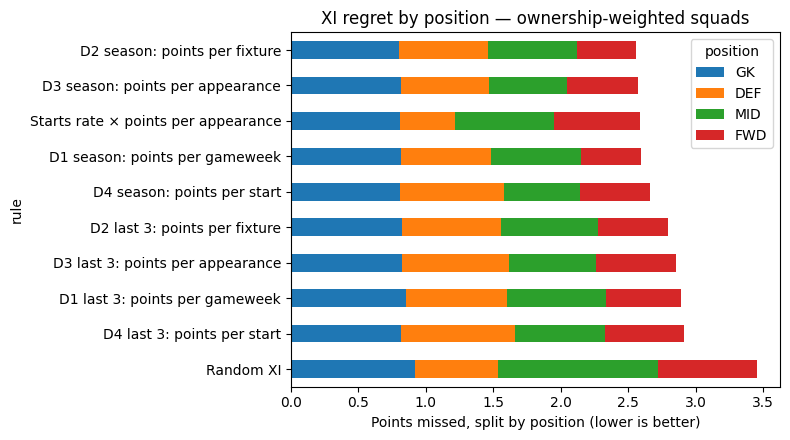

In [8]:
positions = built.positions.loc[MODE, "mean"].astype(float).unstack("position")[["GK", "DEF", "MID", "FWD"]]
positions = positions.loc[rules.index]
ax = labelled(positions).plot.barh(stacked=True, figsize=(8, 4.5))
ax.invert_yaxis()
ax.set_xlabel("Points missed, split by position (lower is better)")
ax.set_title("XI regret by position — ownership-weighted squads")
plt.tight_layout()

**What:** points missed with the goalkeeper slot left out (*outfield only*), with 95% ranges, next to the goalkeeper share.
**Why:** synthetic squads often have two goalkeepers who both played, which real squads rarely do (see caveats).
That makes the goalkeeper slot a coin toss that inflates every rule's misses. Leaving it out shows whether
the ranking holds.
**How:** defenders + midfielders + forwards regret, with the same Gameweek-block range as (a). *Lower is better.*

In [9]:
outfield = rules[["outfield_mean", "outfield_ci_lo", "outfield_ci_hi"]].join(positions["GK"])
outfield.columns = ["Outfield missed", "95% low", "95% high", "GK missed"]
labelled(outfield)

,Outfield missed,95% low,95% high,GK missed
rule,,,,
D2 season: points per fixture,1.76,1.49,2.07,0.80
D3 season: points per appearance,1.76,1.50,2.08,0.81
Starts rate × points per appearance,1.77,1.53,2.06,0.81
D1 season: points per gameweek,1.78,1.53,2.07,0.82
D4 season: points per start,1.85,1.58,2.19,0.81
D2 last 3: points per fixture,1.97,1.64,2.35,0.82
D3 last 3: points per appearance,2.03,1.66,2.46,0.82
D1 last 3: points per gameweek,2.04,1.74,2.38,0.85
D4 last 3: points per start,2.10,1.75,2.53,0.82


## (e) Rule agreement and formations

**What:** for each pair of rules, the share of their 11 picks they have in common.
**Why:** if two rules pick nearly the same players, the choice between them matters little in practice.
**How:** per squad and Gameweek, players picked by both ÷ 11, then averaged. *1.00 means identical picks.*

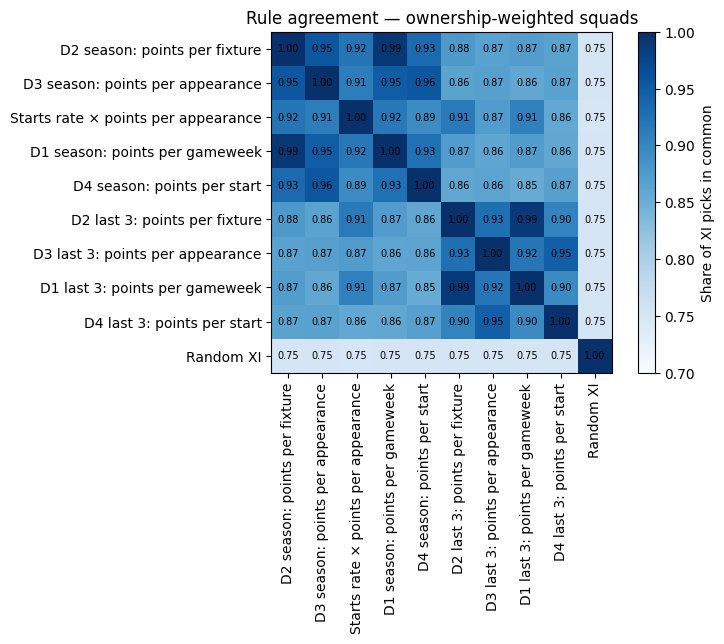

In [10]:
agreement = built.agreement.loc[MODE, "share_in_common"].astype(float)
names = list(rules.index)
grid = pd.DataFrame(1.0, index=names, columns=names)
for (a, b), share in agreement.items():
    grid.loc[a, b] = grid.loc[b, a] = share
fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(grid, vmin=0.7, vmax=1.0, cmap="Blues")
ax.set_xticks(range(len(names)), [LABELS[n] for n in names], rotation=90)
ax.set_yticks(range(len(names)), [LABELS[n] for n in names])
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{grid.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, label="Share of XI picks in common")
ax.set_title("Rule agreement — ownership-weighted squads")
plt.tight_layout()

**What:** how often each formation (defenders-midfielders-forwards) is used by each rule's XI, and by the hindsight-best XI.
**Why:** a rule whose formations differ sharply from the best XI's is leaving points in a systematic place.
**How:** the chosen XI before automatic substitutions; share of squad-Gameweeks per formation. When several
formations tie for the hindsight best, the first in a fixed order (3-4-3 first) is counted, so the best XI's
3-4-3 share is somewhat inflated.

In [11]:
formations = diagnostics.formations.loc[MODE, "share"].astype(float).unstack("formation").fillna(0.0)
formations = formations.loc[["hindsight_ideal", *rules.index]].rename(index={"hindsight_ideal": "Hindsight best XI"})
labelled(formations).style.format("{:.0%}")

formation,3-4-3,3-5-2,4-3-3,4-4-2,4-5-1,5-2-3,5-3-2,5-4-1
picker,,,,,,,,
Hindsight best XI,50%,14%,15%,14%,2%,1%,2%,1%
D2 season: points per fixture,21%,16%,13%,29%,6%,2%,8%,5%
D3 season: points per appearance,19%,18%,11%,30%,8%,1%,8%,5%
Starts rate × points per appearance,16%,12%,14%,31%,7%,2%,11%,7%
D1 season: points per gameweek,22%,16%,14%,28%,6%,2%,8%,4%
D4 season: points per start,23%,20%,11%,27%,7%,1%,6%,4%
D2 last 3: points per fixture,21%,15%,14%,28%,6%,2%,8%,5%
D3 last 3: points per appearance,18%,15%,12%,29%,8%,2%,9%,7%
D1 last 3: points per gameweek,21%,15%,15%,28%,6%,2%,8%,5%


## (f) Caveats

**What:** facts about the synthetic squads that limit how far these numbers carry over to real managers.
**Why:** the decision is about real squads; these are the known ways the test squads differ from them.
**How:** counted over the squads each run used (re-drawn and checked against the run). "Played" means minutes > 0.

- **Goalkeeper inflation.** In about 64% of ownership squad-Gameweeks both keepers played, so the GK slot is a
  live choice far more often than for real managers, who usually own one regular starter. GK misses
  (≈0.8 points for every rule) are inflated; see the outfield-only table in (d).
- **Weighted squads under-include premiums.** Ownership-weighted squads must fit the budget, which drops expensive
  popular players: top premiums appear roughly 30–40% less often than ownership implies, and the squads hold
  about half as many distinct players as uniform ones. These squads are not the real field.
- **Managers see team news.** Every rule here uses only past points; real managers know about injuries and
  rotation before the deadline. A comparison with real managers' own XIs (Stage 5) will favour them.

In [12]:
squads = diagnostics.squads.astype(float)
squads.columns = ["Squad-Gameweeks", "Players who played (mean)", "Players who played (median)",
                  "Share with ≤ 11 who played", "Share with both keepers playing"]
squads.T

squad_mode,ownership,uniform
Squad-Gameweeks,10429.00,10400.00
Players who played (mean),11.86,5.70
Players who played (median),12.00,6.00
Share with ≤ 11 who played,0.37,1.00
Share with both keepers playing,0.64,0.04


## (g) Uniform squads (set aside)

**What:** the same test on *uniform* squads, where every budget-legal squad is equally likely, regardless of
how popular its players are.
**Why it was set aside:** uniform squads are mostly fringe players. On average only about 6 of the 15 played
in a Gameweek (≤ 11 in 99.9% of squad-Gameweeks), so automatic substitutions field nearly the same XI
whatever a rule picks. Every rule's misses are near zero and near each other, so these squads cannot tell
rules apart.
**How to read:** mean points missed per squad per Gameweek, 95% range, and the difference from random.
*Lower is better*; note the scale (hundredths of a point).

In [13]:
uniform = built.rules.loc["uniform"].astype(float)[["xi_mean", "xi_ci_lo", "xi_ci_hi"]]
uniform = uniform.join(built.differences.loc[("uniform", "random"), "mean_diff"].astype(float).rename("vs random"))
uniform.columns = ["Mean missed", "95% low", "95% high", "Minus random"]
labelled(uniform.sort_values("Mean missed")).style.format("{:.3f}", na_rep="—")

,Mean missed,95% low,95% high,Minus random
rule,,,,
Starts rate × points per appearance,0.102,0.084,0.120,-0.016
D2 season: points per fixture,0.104,0.088,0.121,-0.014
D1 season: points per gameweek,0.105,0.088,0.121,-0.013
D3 season: points per appearance,0.106,0.090,0.125,-0.012
D4 season: points per start,0.107,0.091,0.126,-0.011
D2 last 3: points per fixture,0.108,0.093,0.128,-0.010
D4 last 3: points per start,0.109,0.094,0.128,-0.009
D3 last 3: points per appearance,0.110,0.095,0.130,-0.008
D1 last 3: points per gameweek,0.111,0.097,0.131,-0.007
